# 06 · `TD_estado` con LightGBM Poisson

Continuación de `05_lightgbm.ipynb`. Aquí se usa LightGBM con la **misma pérdida Poisson** que `ML_base` y se
reconstruye `TD_estado` (LOG #45) con ese LightGBM en lugar de `ML_base`. Luego se compara con `ML_base`,
`TD_estado` y el resto de los modelos del backtest.

**Qué cambia dentro de `TD_estado`.** `jerarquico.construir` usa `ML_base` en tres lugares, y en `TD_estado_LGBM`
cambian los tres:

| Pieza | `TD_estado` | `TD_estado_LGBM` |
|---|---|---|
| Familia **estable** | `ML_base` | LightGBM Poisson |
| Familia en **caída** → `TD_mix_k3` | (nivel 3 m × índice + Σ `ML_base`) / 2 × cuota `ML_base` | lo mismo con Σ y cuota de LightGBM |
| Familia en **subida** → `TD_mix_k12` | (nivel 12 m × índice + Σ `ML_base`) / 2 × cuota `ML_base` | lo mismo con Σ y cuota de LightGBM |

Los umbrales (0.85 / 1.15), el estado de cada familia, los niveles y los índices estacionales no cambian. Se reusa
la misma función, a la que se le pasa la tabla con `ML_base` sustituido. Como control, la misma función con
`ML_base` reproduce exactamente el `TD_estado` guardado. Código en `src/td_lgbm.py`; no se modifica nada de 01–05.

**LightGBM Poisson.** De las tres configuraciones Poisson de `05` (`L_A`, `L_bag`, `L_C`), la regla WAPE + sesgo en
validación frente a `L_A` elige **`L_C`**: lr 0.03, 600 árboles, 63 hojas, 30 obs. por hoja, columnas al 80 % y
L2 = 1. Una diferencia con `ML_base` que hay que tener presente: `ML_base` usa el *early stopping* automático de
scikit-learn, que con más de 10 mil filas aparta al azar un 10 % y se detiene en 42–63 árboles. LightGBM usa todos
sus árboles y el 100 % de las filas.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from estilo import aplicar, COLORES, AZUL, GRIS, GRIS_CLARO, FMT_MILES
from metricas import resumen, adopta, por_origen, wape, sesgo

aplicar()
pd.set_option("display.width", 220, "display.max_columns", 40)
RES = RAIZ / "data" / "processed" / "resultados"
FIG = RAIZ / "reports" / "figuras"
LG = json.loads((RES / "meta_td_lgbm.json").read_text(encoding="utf-8"))["lgbm_poisson"]
PERIODOS = ["validacion", "prueba"]
d = {p: pd.read_parquet(RES / f"td_lgbm_{p}.parquet") for p in PERIODOS}
print(f"LightGBM Poisson elegido: {LG}")
print({p: len(x) for p, x in d.items()})

LightGBM Poisson elegido: L_C
{'validacion': 9416, 'prueba': 10301}


## 1. Selección del LightGBM Poisson (solo validación)

In [2]:
v = d["validacion"]
t = resumen(v, ["L_A", "L_bag", "L_C"])[["WAPE", "sesgo", "MASE"]]
t["gana_a_L_A"] = [np.nan if m == "L_A" else por_origen(v, [m, "L_A"]).pipe(lambda x: (x[m] < x.L_A).mean()) for m in t.index]
t["cumple_vs_L_A"] = [None if m == "L_A" else adopta(v, m, "L_A") for m in t.index]
print(t.round(3).to_string())

        WAPE  sesgo   MASE  gana_a_L_A cumple_vs_L_A
L_A    0.461  0.158  0.759         NaN          None
L_bag  0.466  0.174  0.758       0.333         False
L_C    0.449  0.122  0.738       0.750          True


## 2. Todos los modelos

Ordenados por WAPE. `gana` = orígenes en que el modelo tiene menor WAPE que la referencia. `cumple` = regla de
adopción (≥ 0.5 pp de WAPE, ≥ 2/3 de los orígenes y no más de 1 pp de |sesgo| extra). `L_tweedie` es el LightGBM
Tweedie de `05`.

In [3]:
MOD = ["SNaive", "Naive", "MA12", "ETS", "Croston", "SBA", "TSB", "SARIMA_fam", "Ruta_clasica",
       "ML_base", LG, "L_tweedie", "TD_mix_k3", f"TD_mix_k3_LGBM", "TD_estado", "TD_estado_LGBM"]

def gana(x, m, ref):
    po = por_origen(x, [m, ref])
    return f"{(po[m] < po[ref]).sum()}/{len(po)}"

tablas = {}
for p in PERIODOS:
    x = d[p]
    r = resumen(x, MOD)[["WAPE", "sesgo", "MASE", "RMSSE", "WAPE_total"]]
    for ref in ("ML_base", "TD_estado"):
        r[f"gana vs {ref}"] = ["" if m == ref else gana(x, m, ref) for m in MOD]
        r[f"cumple vs {ref}"] = ["" if m == ref else adopta(x, m, ref) for m in MOD]
    tablas[p] = r
    print(f"===== {p}")
    print(r.sort_values("WAPE").round(3).to_string()); print()

===== validacion
                 WAPE  sesgo   MASE  RMSSE  WAPE_total gana vs ML_base cumple vs ML_base gana vs TD_estado cumple vs TD_estado
TD_estado_LGBM  0.438  0.094  0.728  0.641       0.169            8/12              True              7/12               False
L_tweedie       0.441  0.113  0.709  0.639       0.175            9/12              True              9/12                True
TD_mix_k3_LGBM  0.443  0.109  0.736  0.645       0.184            8/12              True              6/12               False
L_C             0.449  0.122  0.738  0.647       0.186            7/12             False              8/12                True
TD_mix_k3       0.449  0.144  0.771  0.659       0.198            8/12              True              9/12                True
TD_estado       0.456  0.152  0.771  0.659       0.204            9/12              True                                      
Ruta_clasica    0.459  0.152  0.825  0.687       0.168            6/12             False      

===== prueba
                 WAPE  sesgo   MASE  RMSSE  WAPE_total gana vs ML_base cumple vs ML_base gana vs TD_estado cumple vs TD_estado
TD_estado       0.482  0.016  0.942  0.737       0.087            9/13              True                                      
TD_estado_LGBM  0.483  0.020  0.932  0.734       0.091            8/13             False              8/13               False
ML_base         0.490  0.035  0.952  0.744       0.099                                                4/13               False
L_tweedie       0.491  0.038  0.933  0.739       0.102            8/13             False              6/13               False
L_C             0.493  0.042  0.944  0.742       0.102            7/13             False              6/13               False
TD_mix_k3       0.496  0.043  0.944  0.739       0.103            6/13             False              2/13               False
MA12            0.497  0.037  0.971  0.753       0.107            5/13             False          

**Lectura.**

- **Validación:** `TD_estado_LGBM` tiene el menor WAPE de todos (0.438) y el menor sesgo de los modelos ML/TD
  (+9.5 %). Cumple la regla contra `ML_base`, pero **no contra `TD_estado`**: mejora el WAPE en 1.7 pp, pero solo en
  7 de 12 orígenes.
- **Prueba:** `TD_estado` sigue primero (0.482) y `TD_estado_LGBM` queda segundo, prácticamente empatado (0.483,
  8/13 orígenes, sesgo +2.0 vs +1.6 %). Contra `ML_base`, `TD_estado_LGBM` baja el WAPE en 0.7 pp, pero gana en solo
  8 de 13 orígenes (62 % < 2/3) y **no cumple la regla**. `TD_estado` sí la cumple (9/13).
- **LightGBM Poisson solo (`L_C`)** no le gana a `ML_base` en ninguno de los dos periodos (validación 7/12, prueba
  0.493 vs 0.490).
- **Los clásicos** (Ruta, SBA, MA12, TSB, Croston, SARIMA_fam, ETS, SNaive, Naive) quedan atrás en los dos periodos.
  La ruta clásica tiene buen sesgo en prueba (+1.7 %), pero WAPE 0.497 y peor MASE.

### 2.1 Mano a mano de los cuatro candidatos

In [4]:
C4 = ["ML_base", LG, "TD_estado", "TD_estado_LGBM"]
for p in PERIODOS:
    x = d[p]
    w = wape(x, C4)
    m = pd.DataFrame(index=C4, columns=C4, dtype=object)
    for a in C4:
        for b in C4:
            if a != b:
                po = por_origen(x, [a, b])
                m.loc[a, b] = f"{(w[a] - w[b]) * 100:+.1f} pp · {(po[a] < po[b]).sum()}/{len(po)}" + (" ✓" if adopta(x, a, b) else "")
    print(f"===== {p}  (fila vs columna: Δ WAPE · orígenes ganados · ✓ = cumple la regla)")
    print(m.fillna("—").to_string()); print()

===== validacion  (fila vs columna: Δ WAPE · orígenes ganados · ✓ = cumple la regla)
                         ML_base               L_C         TD_estado  TD_estado_LGBM
ML_base                        —    +2.1 pp · 5/12    +1.4 pp · 3/12  +3.1 pp · 4/12
L_C               -2.1 pp · 7/12                 —  -0.7 pp · 8/12 ✓  +1.0 pp · 3/12
TD_estado       -1.4 pp · 9/12 ✓    +0.7 pp · 4/12                 —  +1.7 pp · 5/12
TD_estado_LGBM  -3.1 pp · 8/12 ✓  -1.0 pp · 9/12 ✓    -1.7 pp · 7/12               —



===== prueba  (fila vs columna: Δ WAPE · orígenes ganados · ✓ = cumple la regla)
                         ML_base               L_C       TD_estado  TD_estado_LGBM
ML_base                        —    -0.3 pp · 6/13  +0.8 pp · 4/13  +0.7 pp · 5/13
L_C               +0.3 pp · 7/13                 —  +1.1 pp · 6/13  +1.0 pp · 4/13
TD_estado       -0.8 pp · 9/13 ✓    -1.1 pp · 7/13               —  -0.1 pp · 5/13
TD_estado_LGBM    -0.7 pp · 8/13  -1.0 pp · 9/13 ✓  +0.1 pp · 8/13               —



## 3. Por estado de la familia

Para ver qué pieza aporta: en las familias **estables** la diferencia es solo `ML_base` vs LightGBM. En **caída** y
**subida**, la diferencia está en la cuota y la Σ de `TD_mix`.

In [5]:
for p in PERIODOS:
    x = d[p]
    g = x.groupby("estado_fam")[C4 + ["y"]]
    t = pd.DataFrame({f"WAPE {m}": g.apply(lambda z: wape(z, [m]).iloc[0]) for m in C4})
    for m in ("TD_estado", "TD_estado_LGBM"):
        t[f"sesgo {m}"] = g.apply(lambda z: sesgo(z, [m]).iloc[0])
    t["% unidades"] = x.groupby("estado_fam").y.sum() / x.y.sum()
    print(f"===== {p}"); print(t.round(3).to_string()); print()

===== validacion
            WAPE ML_base  WAPE L_C  WAPE TD_estado  WAPE TD_estado_LGBM  sesgo TD_estado  sesgo TD_estado_LGBM  % unidades
estado_fam                                                                                                                
caída              0.521     0.519           0.488                0.494            0.099                 0.067       0.412
estable            0.412     0.376           0.412                0.376            0.188                 0.108       0.551
subida             0.742     0.741           0.741                0.739            0.206                 0.199       0.038

===== prueba
            WAPE ML_base  WAPE L_C  WAPE TD_estado  WAPE TD_estado_LGBM  sesgo TD_estado  sesgo TD_estado_LGBM  % unidades
estado_fam                                                                                                                
caída              0.503     0.491           0.489                0.483           -0.027                -0.0

- **Validación:** casi toda la ventaja de `TD_estado_LGBM` está en las familias **estables** (55 % de las unidades).
  Ahí LightGBM baja el WAPE de 0.412 a 0.376 y el sesgo de +19 % a +11 %. En caída, la versión LightGBM recorta el
  sesgo (+10 % → +7 %), pero el WAPE queda casi igual (0.494 vs 0.488).
- **Prueba:** en estables los dos dan 0.457, un empate exacto. En caída y subida se mueven en sentidos opuestos y por
  poco. La ventaja de validación en las familias estables no se repite.

## 4. Por origen

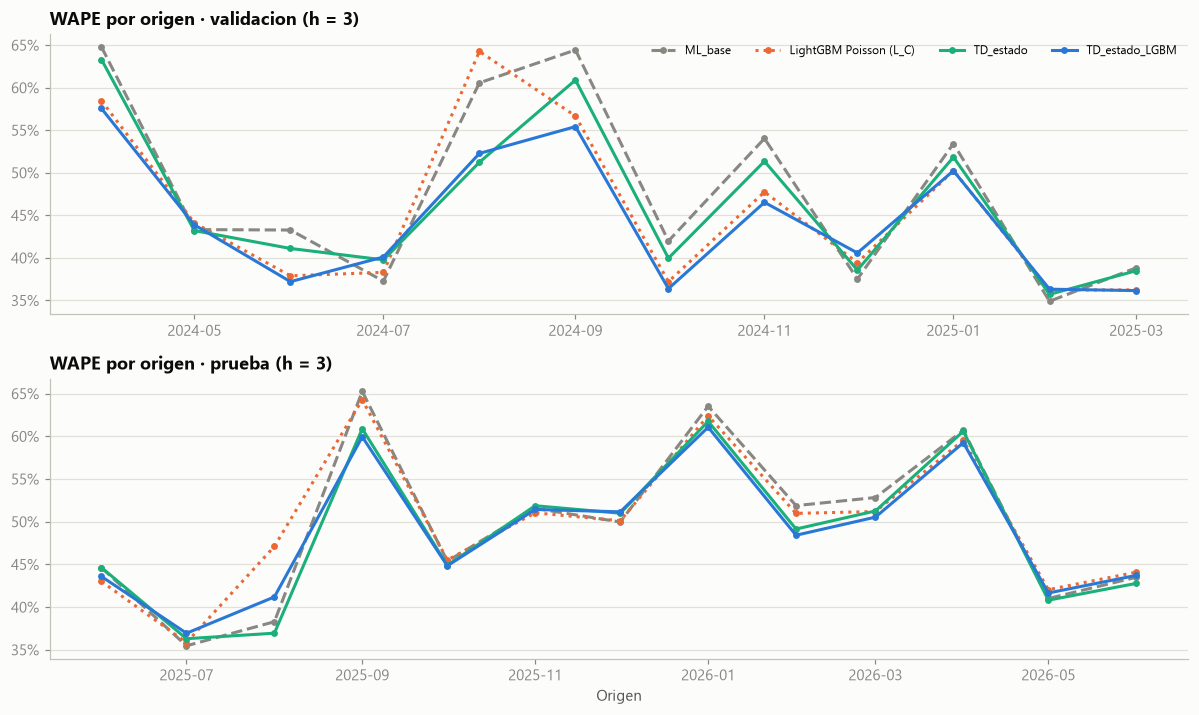

In [6]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6.6))
estilo_m = {"ML_base": dict(color=GRIS, ls="--"), LG: dict(color=COLORES[1], ls=":"),
            "TD_estado": dict(color=COLORES[2]), "TD_estado_LGBM": dict(color=AZUL)}
for a, p in zip(ax, PERIODOS):
    po = por_origen(d[p], C4)
    for m, kw in estilo_m.items():
        a.plot(po.index, po[m], marker="o", ms=3.5, label=m if m != LG else f"LightGBM Poisson ({LG})", **kw)
    a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    a.set_title(f"WAPE por origen · {p} (h = 3)")
ax[0].legend(fontsize=8, ncol=4)
ax[1].set_xlabel("Origen")
fig.tight_layout()
fig.savefig(FIG / "34_td_lgbm_wape_origen.png"); plt.show()

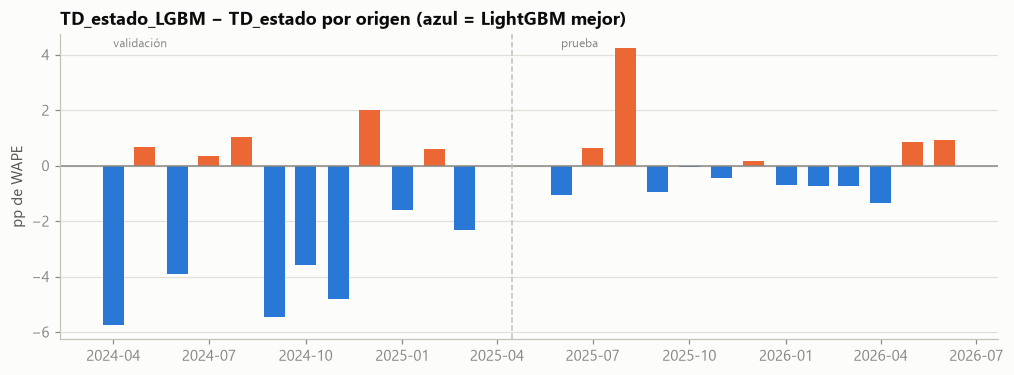

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for i, p in enumerate(PERIODOS):
    po = por_origen(d[p], ["TD_estado", "TD_estado_LGBM"])
    dif = (po.TD_estado_LGBM - po.TD_estado) * 100
    ax.bar(dif.index, dif.values, width=20, color=np.where(dif < 0, AZUL, COLORES[1]))
ax.axhline(0, color=GRIS, lw=1)
ax.axvline(pd.Timestamp("2025-04-15"), color=GRIS_CLARO, lw=1, ls="--")
ax.text(pd.Timestamp("2024-04-01"), ax.get_ylim()[1] * .9, "validación", color=GRIS, fontsize=8)
ax.text(pd.Timestamp("2025-06-01"), ax.get_ylim()[1] * .9, "prueba", color=GRIS, fontsize=8)
ax.set_ylabel("pp de WAPE")
ax.set_title("TD_estado_LGBM − TD_estado por origen (azul = LightGBM mejor)")
fig.savefig(FIG / "35_td_lgbm_diferencia.png"); plt.show()

Las barras alternan de signo en los dos periodos: no hay un patrón sostenido a favor de ninguna versión. La
diferencia más grande es **ago-2025** (prueba): +4.3 pp en contra de LightGBM, el mismo origen en que `L_tweedie`
también falló en `05`.

## 5. Total mensual en prueba

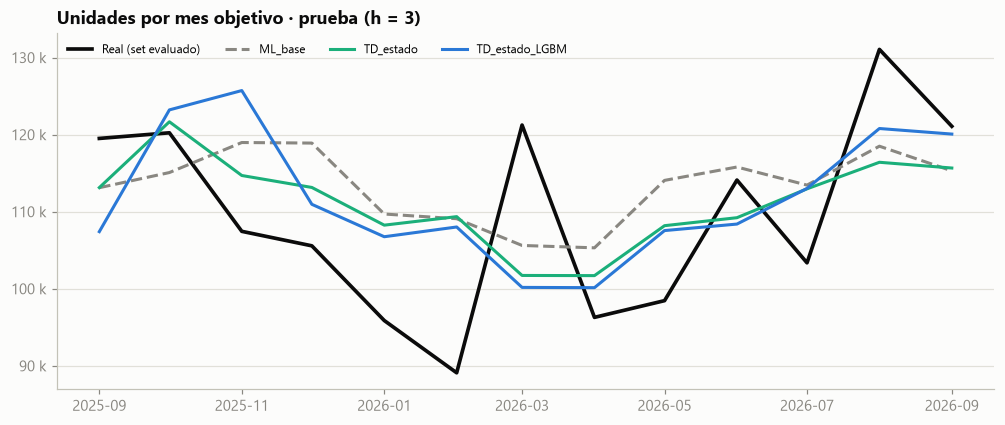

Error del total (pronóstico − real) / real:
mes_obj         2025-09-01  2025-10-01  2025-11-01  2025-12-01  2026-01-01  2026-02-01  2026-03-01  2026-04-01  2026-05-01  2026-06-01  2026-07-01  2026-08-01  2026-09-01
ML_base             -0.053      -0.043       0.107       0.126       0.144       0.224      -0.129       0.094       0.159       0.015       0.098      -0.096      -0.048
TD_estado           -0.053       0.012       0.067       0.072       0.129       0.227      -0.161       0.056       0.099      -0.043       0.093      -0.112      -0.045
TD_estado_LGBM      -0.101       0.025       0.170       0.051       0.113       0.212      -0.174       0.040       0.092      -0.050       0.093      -0.078      -0.008

WAPE del total mensual: {'ML_base': np.float64(0.0988), 'TD_estado': np.float64(0.0875), 'TD_estado_LGBM': np.float64(0.0908)}


In [8]:
x = d["prueba"]
tot = x.groupby("mes_obj")[["y", "ML_base", "TD_estado", "TD_estado_LGBM"]].sum()
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(tot.index, tot.y, color="#0b0b0b", lw=2.4, label="Real (set evaluado)")
ax.plot(tot.index, tot.ML_base, color=GRIS, ls="--", label="ML_base")
ax.plot(tot.index, tot.TD_estado, color=COLORES[2], label="TD_estado")
ax.plot(tot.index, tot.TD_estado_LGBM, color=AZUL, label="TD_estado_LGBM")
ax.yaxis.set_major_formatter(FMT_MILES)
ax.set_title("Unidades por mes objetivo · prueba (h = 3)")
ax.legend(fontsize=8, ncol=4)
fig.savefig(FIG / "36_td_lgbm_total_prueba.png"); plt.show()
e = tot[["ML_base", "TD_estado", "TD_estado_LGBM"]].sub(tot.y, axis=0).div(tot.y, axis=0)
print("Error del total (pronóstico − real) / real:")
print(e.round(3).T.to_string())
print("\nWAPE del total mensual:", {m: round(abs(e[m] * tot.y).sum() / tot.y.sum(), 4) for m in e})

## 6. Hallazgos y decisión

1. **LightGBM Poisson por sí solo no mejora a `ML_base`.** La mejor configuración Poisson (`L_C`) queda 2.1 pp
   abajo en validación, pero solo en 7/12 orígenes, y +0.3 pp arriba en prueba. Esto confirma lo de `05`: con la
   misma pérdida, LightGBM y HistGradientBoosting son equivalentes, aunque LightGBM use 600 árboles y `ML_base` se
   detenga en 42–63.
2. **`TD_estado_LGBM` es el mejor modelo de validación** (WAPE 0.438, sesgo +9.5 %), sobre todo por las familias
   estables. **En prueba empata con `TD_estado`** (0.483 vs 0.482, 8/13 orígenes) y no cumple la regla contra
   `ML_base` (8/13 < 2/3), mientras que `TD_estado` sí la cumple (9/13).
3. **La estructura pesa más que el regresor.** Pasar de `ML_base` a `TD_estado` mejora en los dos periodos, sea cual
   sea el regresor: −1.4 pp / −0.8 pp con HistGradientBoosting y −1.0 pp / −1.0 pp con LightGBM, comparando cada
   `TD_estado` con su propio ML (validación / prueba). Cambiar el regresor dentro de `TD_estado` mueve −1.7 pp en
   validación y +0.1 pp en prueba, sin una dirección estable.
4. **Decisión: `TD_estado` con `ML_base` se mantiene** como pronóstico de los SKUs maduros. Las dos versiones empatan
   en prueba y la vigente es la que cumple la regla en los dos periodos. Cambiar obligaría a regenerar inventario y
   pedido sin una mejora demostrada. `TD_estado_LGBM` queda como **alternativa equivalente** y candidato en el
   reentrenamiento mensual. Si en los próximos meses gana con margen, el cambio es directo: `td_lgbm.py` ya lo
   construye con la misma función.

## 7. Variante Tweedie: `TD_estado_LGBM_tw`

Igual que `TD_estado_LGBM`, pero con el LightGBM **Tweedie** de `05` (`L_tweedie`, potencia 1.5, elegido en
validación entre las 4 configuraciones). Se cambian las mismas tres piezas: la rama estable y la cuota y Σ ML de
`TD_mix_k3` / `TD_mix_k12`. Recordatorio de `05`: Tweedie recorta el sobre-pronóstico y mejora a los SKUs chicos e
intermitentes.

In [9]:
C6 = ["ML_base", LG, "L_tweedie", "TD_estado", "TD_estado_LGBM", "TD_estado_LGBM_tw"]
for p in PERIODOS:
    x = d[p]
    r = resumen(x, C6)[["WAPE", "sesgo", "MASE", "RMSSE", "WAPE_total"]]
    for ref in ("ML_base", "TD_estado"):
        r[f"gana vs {ref}"] = ["" if m == ref else gana(x, m, ref) for m in C6]
        r[f"cumple vs {ref}"] = ["" if m == ref else adopta(x, m, ref) for m in C6]
    print(f"===== {p}"); print(r.round(4).to_string()); print()

===== validacion
                     WAPE   sesgo    MASE   RMSSE  WAPE_total gana vs ML_base cumple vs ML_base gana vs TD_estado cumple vs TD_estado
ML_base            0.4693  0.1932  0.7880  0.6663      0.2227                                                3/12               False
L_C                0.4485  0.1223  0.7384  0.6465      0.1860            7/12             False              8/12                True
L_tweedie          0.4406  0.1130  0.7087  0.6389      0.1749            9/12              True              9/12                True
TD_estado          0.4556  0.1520  0.7712  0.6593      0.2042            9/12              True                                      
TD_estado_LGBM     0.4382  0.0945  0.7284  0.6415      0.1686            8/12              True              7/12               False
TD_estado_LGBM_tw  0.4358  0.0930  0.7027  0.6365      0.1647            8/12              True              9/12                True



===== prueba
                     WAPE   sesgo    MASE   RMSSE  WAPE_total gana vs ML_base cumple vs ML_base gana vs TD_estado cumple vs TD_estado
ML_base            0.4902  0.0348  0.9516  0.7438      0.0988                                                4/13               False
L_C                0.4929  0.0417  0.9445  0.7425      0.1019            7/13             False              6/13               False
L_tweedie          0.4912  0.0376  0.9332  0.7391      0.1019            8/13             False              6/13               False
TD_estado          0.4822  0.0160  0.9420  0.7375      0.0875            9/13              True                                      
TD_estado_LGBM     0.4832  0.0203  0.9320  0.7338      0.0908            8/13             False              8/13               False
TD_estado_LGBM_tw  0.4831  0.0201  0.9237  0.7325      0.0942           10/13              True              9/13               False



### 7.1 Por estado de la familia y por origen

In [10]:
C3 = ["TD_estado", "TD_estado_LGBM", "TD_estado_LGBM_tw"]
for p in PERIODOS:
    x = d[p]
    g = x.groupby("estado_fam")[C3 + ["y"]]
    t = pd.DataFrame({f"WAPE {m}": g.apply(lambda z: wape(z, [m]).iloc[0]) for m in C3})
    for m in C3:
        t[f"sesgo {m}"] = g.apply(lambda z: sesgo(z, [m]).iloc[0])
    t["% unidades"] = x.groupby("estado_fam").y.sum() / x.y.sum()
    print(f"===== {p}"); print(t.round(3).to_string()); print()

===== validacion
            WAPE TD_estado  WAPE TD_estado_LGBM  WAPE TD_estado_LGBM_tw  sesgo TD_estado  sesgo TD_estado_LGBM  sesgo TD_estado_LGBM_tw  % unidades
estado_fam                                                                                                                                         
caída                0.488                0.494                   0.477            0.099                 0.067                    0.048       0.412
estable              0.412                0.376                   0.384            0.188                 0.108                    0.120       0.551
subida               0.741                0.739                   0.737            0.206                 0.199                    0.193       0.038

===== prueba
            WAPE TD_estado  WAPE TD_estado_LGBM  WAPE TD_estado_LGBM_tw  sesgo TD_estado  sesgo TD_estado_LGBM  sesgo TD_estado_LGBM_tw  % unidades
estado_fam                                                                       

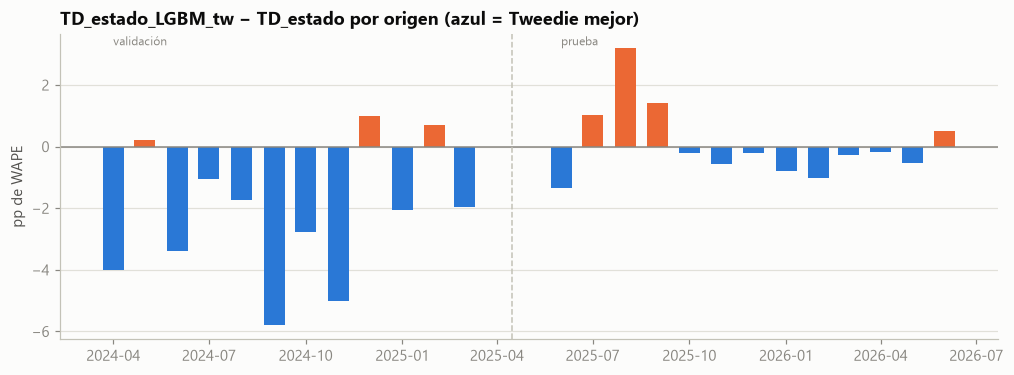

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.6))
for p in PERIODOS:
    po = por_origen(d[p], ["TD_estado", "TD_estado_LGBM_tw"])
    dif = (po.TD_estado_LGBM_tw - po.TD_estado) * 100
    ax.bar(dif.index, dif.values, width=20, color=np.where(dif < 0, AZUL, COLORES[1]))
ax.axhline(0, color=GRIS, lw=1)
ax.axvline(pd.Timestamp("2025-04-15"), color=GRIS_CLARO, lw=1, ls="--")
ax.text(pd.Timestamp("2024-04-01"), ax.get_ylim()[1] * .9, "validación", color=GRIS, fontsize=8)
ax.text(pd.Timestamp("2025-06-01"), ax.get_ylim()[1] * .9, "prueba", color=GRIS, fontsize=8)
ax.set_ylabel("pp de WAPE")
ax.set_title("TD_estado_LGBM_tw − TD_estado por origen (azul = Tweedie mejor)")
fig.savefig(FIG / "37_td_lgbm_tw_diferencia.png"); plt.show()

### 7.2 Lectura

| | Validación | Prueba |
|---|---|---|
| WAPE `TD_estado` → `TD_estado_LGBM_tw` | 0.456 → **0.436** (9/12 orígenes) ✓ | 0.482 → 0.483 (9/13 orígenes) ✗ por WAPE |
| Sesgo | +15.2 % → +9.3 % | +1.6 % → +2.0 % |
| MASE | 0.771 → 0.703 | 0.942 → **0.924** (el mejor de todos los modelos) |
| Contra `ML_base` | cumple (8/12) | **cumple** (−0.7 pp, 10/13, sesgo +2.0 vs +3.5 %) |

1. **Es la mejor variante con LightGBM.** Supera a `TD_estado_LGBM` (Poisson) en los dos periodos, aunque por poco
   (0.436 vs 0.438 y 0.4831 vs 0.4832), y tiene el mejor MASE de todo el backtest en los dos periodos.
2. **Es el único modelo, aparte de `TD_estado`, que cumple la regla contra `ML_base` en validación y en prueba.**
   Además, en validación cumple la regla contra el propio `TD_estado`.
3. **En prueba empata con `TD_estado`:** gana en 9 de 13 orígenes, pero el WAPE total queda 0.1 pp arriba. Sus
   victorias por origen son chicas y sus derrotas más grandes (ago-2025 +3.2 pp, sep-2025 +1.4 pp). La regla exige
   0.5 pp de mejora, así que no la cumple.
4. **A favor del cambio:** su selección es más limpia. Tweedie y su potencia se eligieron solo con validación,
   mientras que la rama de subidas de `TD_estado` se definió viendo prueba (riesgo anotado en LOG #45). También es
   mejor en los SKUs chicos e intermitentes (MASE).
5. **En contra:** no mejora el WAPE ni el sesgo en prueba, agrega una dependencia (LightGBM) y obliga a regenerar
   inventario y pedido.

**Decisión pendiente del usuario.** Con la regla vigente, `TD_estado` se mantiene porque en prueba no hay mejora de
WAPE. `TD_estado_LGBM_tw` es la alternativa más sólida probada hasta ahora y el primer candidato para el
reentrenamiento mensual. Antes de cambiar, conviene comparar el inventario (stock a igual fill rate), como se hizo
con `TD_estado` en `03_inventario`.